
# Notebook 01 - Build the Northstar Hydration CPG World

## Objective

I am creating a realistic synthetic **CPG market × week dataset** for a fictional premium functional beverage brand.

The dataset is intentionally designed to support later work on:

- Marketing Mix Modeling (MMM)
- Incrementality / geo lift testing
- Bayesian calibration of MMM with experimental evidence
- Base-price elasticity
- Promotions and trade-offs between volume and margin
- Competitor pricing
- Distribution effects
- Profit-oriented commercial optimization

### Core business question

> **Should Northstar Hydration grow by increasing media, lowering price, running deeper promotions, or using some combination of those levers?**

This first notebook does **not** fit any model. It creates the fictional business environment and the historical data that later notebooks will analyze.

---

## Important simulation principle

Because this is synthetic data, **we know the true data-generating process**.

That gives us a useful benchmark:

- the modeling dataset contains only variables an analyst could plausibly observe;
- the simulation code contains the hidden causal truth;
- later we can test whether MMM and pricing models recover that truth;
- we can deliberately introduce confounding so that observational estimates are not automatically causal.

This makes the later incrementality work meaningful rather than decorative.



## Northstar Hydration

Northstar Hydration sells a **premium 4-pack of functional electrolyte beverages** through grocery, mass retail, and convenience channels.

### Commercial setup

- Typical shelf price: **$9.99**
- Common promotion: **10% off**
- Deep promotion: **20% off**
- Manufacturer unit COGS: **$3.40**
- Approximate retailer margin: **30%**
- Geography: **20 U.S. markets**
- History: **104 weeks**
- Media channels:
  - Connected TV
  - Paid Social
  - Retail Media
  - Paid Search

### Why this is useful

CPG demand is influenced by much more than advertising. We will simulate:

- own price;
- competitor price;
- promotions;
- distribution;
- seasonality;
- media;
- market-level brand strength;
- latent demand shocks.

Some media spend will intentionally rise when demand is already strong. This creates a realistic source of **confounding** that later lift tests can help correct.


In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# Set to True in Google Colab if you want all project files persisted in Drive.
USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/northstar_cpg")
    except ImportError:
        # Fallback when the notebook is run outside Google Colab.
        PROJECT_DIR = Path("/content/northstar_cpg")
else:
    PROJECT_DIR = Path("/content/northstar_cpg")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project folder: {PROJECT_DIR}")

Mounted at /content/drive
Project folder: /content/drive/MyDrive/northstar_cpg



## 1. Define the hidden business truth

These values define the fictional universe.

They are **not estimates**. Later models will try to recover them from the observed data.

A few assumptions:

- Own-price elasticity varies modestly by market around a national mean.
- Promotions create an additional merchandising/display effect beyond the mechanical price reduction.
- Media has both **carryover (adstock)** and **diminishing returns (saturation)**.
- Connected TV has the longest carryover.
- Paid Social is intentionally exposed to more confounding so that observational MMM may over-credit it.


In [ ]:
TRUTH = {
    "reference_price": 9.99,
    "unit_cogs": 3.40,
    "retailer_margin": 0.30,
    "national_price_elasticity_mean": -1.40,
    "competitor_price_elasticity": 0.45,
    "distribution_elasticity": 1.10,
    "promo_merchandising_log_lift_10pct": 0.055,
    "promo_merchandising_log_lift_20pct": 0.105,
    "observation_noise_sigma": 0.075,
    "channels": {
        "ctv": {
            "adstock_alpha": 0.70,
            "half_saturation_spend": 12000,
            "max_log_demand_lift": 0.18,
        },
        "social": {
            "adstock_alpha": 0.35,
            "half_saturation_spend": 6500,
            "max_log_demand_lift": 0.14,
        },
        "retail_media": {
            "adstock_alpha": 0.25,
            "half_saturation_spend": 5000,
            "max_log_demand_lift": 0.16,
        },
        "search": {
            "adstock_alpha": 0.10,
            "half_saturation_spend": 3000,
            "max_log_demand_lift": 0.10,
        },
    },
}

pd.DataFrame({
    "parameter": [
        "Reference shelf price",
        "Manufacturer COGS / pack",
        "Retailer margin",
        "National mean own-price elasticity",
        "Competitor-price elasticity",
        "Distribution elasticity",
        "Observation noise sigma",
    ],
    "true_value": [
        TRUTH["reference_price"],
        TRUTH["unit_cogs"],
        TRUTH["retailer_margin"],
        TRUTH["national_price_elasticity_mean"],
        TRUTH["competitor_price_elasticity"],
        TRUTH["distribution_elasticity"],
        TRUTH["observation_noise_sigma"],
    ],
})


,parameter,true_value
0,Reference shelf price,9.990
1,Manufacturer COGS / pack,3.400
2,Retailer margin,0.300
3,National mean own-price elasticity,-1.400
4,Competitor-price elasticity,0.450
5,Distribution elasticity,1.100
6,Observation noise sigma,0.075



## 2. Helper functions: adstock and saturation

We will use two standard MMM ideas.

### Geometric adstock

Advertising can continue affecting demand after the week in which the spend occurs.

\[
A_t = X_t + \alpha A_{t-1}
\]

Higher `alpha` means longer carryover.

### Saturation

The incremental effect of media should not grow linearly forever. We use a simple saturating response:

\[
S(x) = \frac{x}{x + k}
\]

where `k` is the half-saturation point.


In [ ]:
def geometric_adstock(x, alpha):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x, dtype=float)

    for i, value in enumerate(x):
        out[i] = value if i == 0 else value + alpha * out[i - 1]

    return out


def saturation(x, half_saturation):
    x = np.asarray(x, dtype=float)
    return x / (x + half_saturation)


## 3. Build the market × week panel

In [ ]:

markets = [
    "Atlanta", "Boston", "Charlotte", "Chicago", "Dallas",
    "Denver", "Detroit", "Houston", "Los Angeles", "Miami",
    "Minneapolis", "Nashville", "New York", "Orlando", "Philadelphia",
    "Phoenix", "San Diego", "San Francisco", "Seattle", "Washington DC",
]

weeks = pd.date_range("2024-01-01", periods=104, freq="W-MON")

panel = pd.MultiIndex.from_product(
    [markets, weeks],
    names=["market", "week"]
).to_frame(index=False)

panel["week_number"] = panel.groupby("market").cumcount()
panel["year"] = panel["week"].dt.year
panel["month"] = panel["week"].dt.month

print(panel.shape)
panel.head()


(2080, 5)


,market,week,week_number,year,month
0,Atlanta,2024-01-01,0,2024,1
1,Atlanta,2024-01-08,1,2024,1
2,Atlanta,2024-01-15,2,2024,1
3,Atlanta,2024-01-22,3,2024,1
4,Atlanta,2024-01-29,4,2024,1



## 4. Market characteristics

Markets differ in:

- addressable category size;
- Northstar brand strength;
- starting distribution;
- price sensitivity.

This heterogeneity is useful later when we introduce hierarchical models or geo experiments.


In [ ]:

market_profile = pd.DataFrame({
    "market": markets,
    "market_size_factor": rng.uniform(0.75, 1.35, len(markets)),
    "brand_strength": rng.uniform(0.90, 1.12, len(markets)),
    "starting_distribution": rng.uniform(0.58, 0.82, len(markets)),
    "price_elasticity": np.clip(
        rng.normal(TRUTH["national_price_elasticity_mean"], 0.22, len(markets)),
        -1.95,
        -0.90,
    ),
    "media_intensity": rng.uniform(0.80, 1.20, len(markets)),
})

panel = panel.merge(market_profile, on="market", how="left")

market_profile.sort_values("market").head(10)


,market,market_size_factor,brand_strength,starting_distribution,price_elasticity,media_intensity
0,Atlanta,1.214374,1.066779,0.684916,-1.590483,1.065725
1,Boston,1.013327,0.977996,0.779843,-1.186979,0.962555
2,Charlotte,1.265159,1.113554,0.748064,-1.770231,1.125608
3,Chicago,1.168421,1.096487,0.654968,-1.473675,0.866789
4,Dallas,0.806506,1.071244,0.779742,-1.364194,0.809085
5,Denver,1.335373,0.942821,0.773143,-1.271031,0.836019
6,Detroit,1.206684,1.002679,0.672995,-1.243530,1.088944
7,Houston,1.221639,0.909637,0.649199,-1.225464,0.984751
8,Los Angeles,0.826868,0.933944,0.743799,-1.476720,0.864509
9,Miami,1.020232,1.050271,0.613541,-1.501717,1.000418



## 5. Seasonality and latent demand

Hydration demand peaks in warmer months.

We also create an **unobserved local demand shock**. Think of this as local buzz, weather, events, or other short-lived demand conditions not perfectly captured in the analyst's dataset.

Later, some media spend will respond to this hidden demand signal. That is one source of endogeneity.


In [ ]:

# Smooth annual seasonality with a summer peak.
day_of_year = panel["week"].dt.dayofyear.to_numpy()
panel["seasonality_index"] = (
    1.0
    + 0.15 * np.sin(2 * np.pi * (day_of_year - 105) / 365.25)
    + 0.035 * np.sin(4 * np.pi * (day_of_year - 20) / 365.25)
)

# A few category-relevant seasonal/event weeks.
panel["summer_event"] = (
    ((panel["month"] == 5) & (panel["week"].dt.day >= 20))
    | (panel["month"] == 7)
    | ((panel["month"] == 9) & (panel["week"].dt.day <= 10))
).astype(int)

# Market-specific latent AR(1) demand shock.
latent_parts = []

for market, g in panel.groupby("market", sort=False):
    shocks = np.zeros(len(g))
    innovations = rng.normal(0, 0.045, len(g))

    for t in range(1, len(g)):
        shocks[t] = 0.60 * shocks[t - 1] + innovations[t]

    tmp = g[["market", "week"]].copy()
    tmp["latent_demand_shock"] = shocks
    latent_parts.append(tmp)

latent = pd.concat(latent_parts, ignore_index=True)
panel = panel.merge(latent, on=["market", "week"], how="left")


## 6. Distribution

In [ ]:

# Distribution gradually expands over the two years.
growth_curve = panel["week_number"] / (panel["week_number"].max())

panel["distribution"] = (
    panel["starting_distribution"]
    + 0.10 * growth_curve
    + rng.normal(0, 0.012, len(panel))
).clip(0.50, 0.96)



## 7. Northstar price, promotions, and competitor price

A few deliberate choices:

- Northstar takes a modest list-price increase in year 2.
- Markets have small permanent price differences.
- Promotions are **more likely when underlying demand is soft**, creating pricing endogeneity.
- Competitor price follows its own market-level path.


In [ ]:

market_price_offset = {
    market: offset
    for market, offset in zip(markets, rng.normal(0, 0.14, len(markets)))
}

panel["base_price"] = (
    TRUTH["reference_price"]
    + panel["market"].map(market_price_offset)
    + np.where(panel["week_number"] >= 60, 0.35, 0.0)
)

# Promotions are more likely in softer-demand periods.
soft_demand = (
    -0.55 * (panel["seasonality_index"] - 1.0)
    -0.85 * panel["latent_demand_shock"]
)

promo_probability = np.clip(
    0.15 + soft_demand + 0.025 * panel["summer_event"],
    0.05,
    0.42,
)

promo_draw = rng.random(len(panel))
deep_draw = rng.random(len(panel))

panel["promo_depth"] = 0.0
panel.loc[promo_draw < promo_probability, "promo_depth"] = 0.10
panel.loc[
    (promo_draw < promo_probability) & (deep_draw < 0.22),
    "promo_depth"
] = 0.20

panel["promo_flag"] = (panel["promo_depth"] > 0).astype(int)
panel["actual_price"] = panel["base_price"] * (1 - panel["promo_depth"])

# Competitor pricing: market offset + slow drift + noise.
competitor_market_offset = {
    market: offset
    for market, offset in zip(markets, rng.normal(0, 0.18, len(markets)))
}

panel["competitor_price"] = (
    9.49
    + panel["market"].map(competitor_market_offset)
    + 0.20 * (panel["week_number"] / 103)
    + rng.normal(0, 0.09, len(panel))
).clip(8.75, 10.75)

panel["relative_price_index"] = panel["actual_price"] / panel["competitor_price"]



## 8. Media spend

Media planning is intentionally not random.

Examples of realistic behavior:

- CTV is pulsed and heavier during seasonal growth periods.
- Social increases when both seasonal demand and local buzz are strong.
- Retail media increases around promotions.
- Search responds partly to category demand.

That means simple correlations between spend and sales will **not** equal causal effects.


In [ ]:

size_scale = panel["market_size_factor"]
media_scale = panel["media_intensity"]
season_scale = 0.85 + 0.45 * panel["seasonality_index"]

# CTV: pulsed, larger bursts.
ctv_active = rng.random(len(panel)) < (
    0.48 + 0.22 * (panel["seasonality_index"] > 1.05)
)
panel["ctv_spend"] = (
    ctv_active
    * rng.gamma(shape=3.0, scale=2600, size=len(panel))
    * size_scale
    * media_scale
    * season_scale
)

# Social: always-on and deliberately correlated with latent demand.
social_multiplier = np.exp(
    0.45 * (panel["seasonality_index"] - 1.0)
    + 1.35 * panel["latent_demand_shock"]
)
panel["social_spend"] = (
    rng.gamma(shape=4.0, scale=1200, size=len(panel))
    * size_scale
    * media_scale
    * social_multiplier
)

# Retail media: closely associated with promotional activity.
panel["retail_media_spend"] = (
    rng.gamma(shape=3.2, scale=1050, size=len(panel))
    * size_scale
    * media_scale
    * (1 + 0.95 * panel["promo_flag"])
)

# Search: responds to category demand and local demand conditions.
search_multiplier = np.exp(
    0.30 * (panel["seasonality_index"] - 1.0)
    + 0.70 * panel["latent_demand_shock"]
)
panel["search_spend"] = (
    rng.gamma(shape=3.0, scale=650, size=len(panel))
    * size_scale
    * media_scale
    * search_multiplier
)

spend_cols = [
    "ctv_spend",
    "social_spend",
    "retail_media_spend",
    "search_spend",
]

panel["total_media_spend"] = panel[spend_cols].sum(axis=1)


## 9. Apply adstock and saturation

In [ ]:

for channel, params in TRUTH["channels"].items():
    spend_col = f"{channel}_spend"
    adstock_col = f"true_{channel}_adstock"
    sat_col = f"true_{channel}_saturation"

    panel[adstock_col] = (
        panel.groupby("market", sort=False)[spend_col]
        .transform(lambda s: geometric_adstock(s.to_numpy(), params["adstock_alpha"]))
    )

    panel[sat_col] = saturation(
        panel[adstock_col].to_numpy(),
        params["half_saturation_spend"]
    )



## 10. Generate unit demand

Demand is multiplicative, so we generate it on a log scale.

Conceptually:

\[
\log(Q) =
\text{market baseline}
+ \text{seasonality}
+ \text{price effect}
+ \text{competitor effect}
+ \text{promotion effect}
+ \text{distribution effect}
+ \text{media effects}
+ \text{latent demand}
+ \epsilon
\]

The model later will *not* observe `latent_demand_shock` or the true transformed media variables.


In [ ]:

REFERENCE_WEEKLY_UNITS = 18000

# Baseline market demand.
log_demand = (
    np.log(REFERENCE_WEEKLY_UNITS)
    + np.log(panel["market_size_factor"])
    + np.log(panel["brand_strength"])
)

# Seasonality and special events.
log_demand += np.log(panel["seasonality_index"])
log_demand += 0.045 * panel["summer_event"]

# Own-price elasticity.
log_demand += (
    panel["price_elasticity"]
    * np.log(panel["actual_price"] / TRUTH["reference_price"])
)

# Competitor-price effect.
log_demand += (
    TRUTH["competitor_price_elasticity"]
    * np.log(panel["competitor_price"] / 9.49)
)

# Promotion merchandising/display effect beyond the shelf-price effect.
promo_merch_lift = np.select(
    [panel["promo_depth"] == 0.10, panel["promo_depth"] == 0.20],
    [
        TRUTH["promo_merchandising_log_lift_10pct"],
        TRUTH["promo_merchandising_log_lift_20pct"],
    ],
    default=0.0,
)
log_demand += promo_merch_lift

# Distribution effect.
log_demand += (
    TRUTH["distribution_elasticity"]
    * np.log(panel["distribution"] / 0.72)
)

# Media effects.
for channel, params in TRUTH["channels"].items():
    log_demand += (
        params["max_log_demand_lift"]
        * panel[f"true_{channel}_saturation"]
    )

# Hidden local demand.
log_demand += panel["latent_demand_shock"]

# Observation noise.
log_demand += rng.normal(
    0,
    TRUTH["observation_noise_sigma"],
    len(panel)
)

panel["units"] = np.round(np.exp(log_demand)).astype(int)



## 11. Convert demand into revenue and profit

We distinguish:

- **retail_sales**: consumer shelf-price sales;
- **manufacturer_net_revenue**: simplified manufacturer revenue after retailer margin;
- **gross_profit_before_media**: manufacturer revenue minus product COGS;
- **contribution_profit_after_media**: gross profit minus measured media spend.

This is intentionally simplified. Later we can add trade-spend funding, retailer allowances, or channel-specific economics if needed.


In [ ]:

panel["retail_sales"] = panel["units"] * panel["actual_price"]

panel["manufacturer_net_revenue"] = (
    panel["retail_sales"] * (1 - TRUTH["retailer_margin"])
)

panel["product_cogs"] = panel["units"] * TRUTH["unit_cogs"]

panel["gross_profit_before_media"] = (
    panel["manufacturer_net_revenue"] - panel["product_cogs"]
)

panel["contribution_profit_after_media"] = (
    panel["gross_profit_before_media"] - panel["total_media_spend"]
)



## 12. Create the analyst-facing modeling dataset

The modeling dataset excludes simulation-only variables such as:

- the true market elasticity;
- latent demand shocks;
- true adstock;
- true saturation.

Those hidden columns would create leakage.

We keep them in `simulation_truth` only so that **we**, as the simulation designers, can validate later models.


In [ ]:

model_cols = [
    "week",
    "market",
    "week_number",
    "year",
    "month",
    "units",
    "retail_sales",
    "manufacturer_net_revenue",
    "gross_profit_before_media",
    "contribution_profit_after_media",
    "base_price",
    "actual_price",
    "promo_depth",
    "promo_flag",
    "competitor_price",
    "relative_price_index",
    "distribution",
    "ctv_spend",
    "social_spend",
    "retail_media_spend",
    "search_spend",
    "total_media_spend",
    "summer_event",
    "seasonality_index",
]

modeling_data = (
    panel[model_cols]
    .sort_values(["week", "market"])
    .reset_index(drop=True)
)

simulation_truth = panel.copy()

print("Modeling data shape:", modeling_data.shape)
modeling_data.head()


Modeling data shape: (2080, 24)


,week,market,week_number,year,month,units,retail_sales,manufacturer_net_revenue,gross_profit_before_media,contribution_profit_after_media,...,competitor_price,relative_price_index,distribution,ctv_spend,social_spend,retail_media_spend,search_spend,total_media_spend,summer_event,seasonality_index
0,2024-01-01,Atlanta,0,2024,1,23663,241399.493440,168979.645408,88525.445408,78774.424119,...,9.634526,1.058854,0.692153,0.000000,3903.727442,4221.852802,1625.441045,9751.021289,0,0.832274
1,2024-01-01,Boston,0,2024,1,21680,215461.829159,150823.280411,77111.280411,55655.807923,...,9.223515,1.077493,0.793102,10004.174275,6238.589426,833.127225,4379.581561,21455.472488,0,0.832274
2,2024-01-01,Charlotte,0,2024,1,28290,283772.853647,198640.997553,102454.997553,86375.002478,...,9.679983,1.036247,0.728758,6196.089517,1692.947724,5641.816389,2549.141445,16079.995075,0,0.832274
3,2024-01-01,Chicago,0,2024,1,21840,221603.320671,155122.324469,80866.324469,72521.010366,...,9.696447,1.046432,0.664752,0.000000,4461.380167,2103.378947,1780.554989,8345.314103,0,0.832274
4,2024-01-01,Dallas,0,2024,1,15813,156938.482760,109856.937932,56092.737932,35856.439884,...,9.349673,1.061497,0.760444,14682.126378,2191.366859,1190.037680,2172.767131,20236.298048,0,0.832274


## 13. Sanity checks

In [ ]:

summary = modeling_data[
    [
        "units",
        "actual_price",
        "promo_depth",
        "competitor_price",
        "distribution",
        "ctv_spend",
        "social_spend",
        "retail_media_spend",
        "search_spend",
        "contribution_profit_after_media",
    ]
].describe().T

summary


,count,mean,std,min,25%,50%,75%,max
units,2080.0,28744.646154,7904.568735,13021.000000,22936.750000,27463.500000,33440.000000,68062.000000
actual_price,2080.0,9.952832,0.533294,7.849620,9.896039,10.097266,10.285834,10.598176
promo_depth,2080.0,0.020144,0.048080,0.000000,0.000000,0.000000,0.000000,0.200000
competitor_price,2080.0,9.486755,0.226497,8.880047,9.311523,9.475973,9.659590,10.067634
distribution,2080.0,0.748400,0.072348,0.568849,0.690319,0.755580,0.806264,0.893619
ctv_spend,2080.0,6017.395251,7259.867202,0.000000,0.000000,4032.419596,9862.655745,51677.036741
social_spend,2080.0,5225.275589,2968.601617,486.635397,3032.340253,4650.793389,6623.642942,20380.628478
retail_media_spend,2080.0,4160.411557,2965.472723,151.544692,2126.489458,3459.245971,5360.313501,26105.837069
search_spend,2080.0,2046.245550,1268.425494,56.498276,1089.100894,1789.399808,2647.186568,9895.859143
contribution_profit_after_media,2080.0,84249.891080,25095.961719,17062.505821,65832.627957,80982.829647,99156.145979,183852.554309


In [ ]:

print("Promotion rate:", round(modeling_data["promo_flag"].mean(), 3))
print("Deep-promo rate:", round((modeling_data["promo_depth"] == 0.20).mean(), 3))
print("Average shelf price:", round(modeling_data["actual_price"].mean(), 2))
print("Average weekly units per market:", round(modeling_data["units"].mean(), 0))
print("Average distribution:", round(modeling_data["distribution"].mean(), 3))
print("Average weekly media spend per market:", round(modeling_data["total_media_spend"].mean(), 0))


Promotion rate: 0.166
Deep-promo rate: 0.035
Average shelf price: 9.95
Average weekly units per market: 28745.0
Average distribution: 0.748
Average weekly media spend per market: 17449.0



## 14. Visual checks

These are not causal analyses. They simply help us confirm that the simulated data looks like a plausible business history.


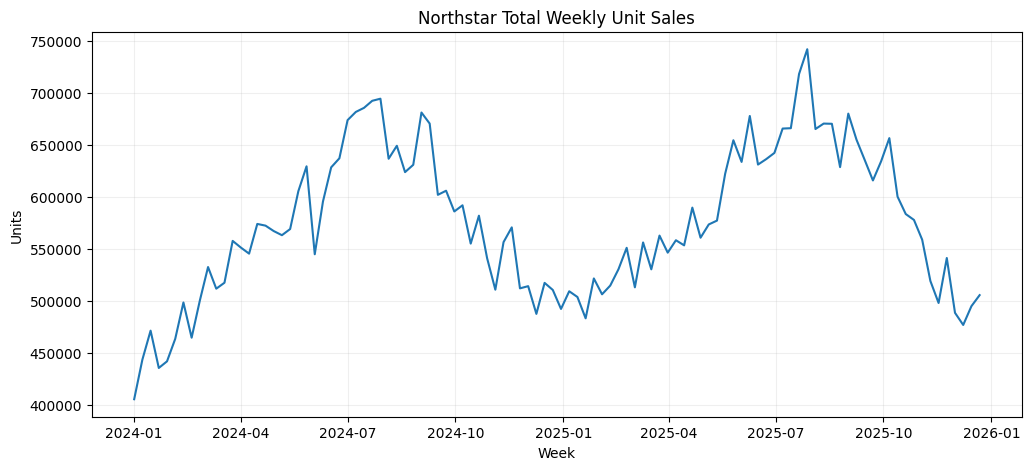

In [ ]:

weekly = (
    modeling_data.groupby("week", as_index=False)
    .agg(
        units=("units", "sum"),
        total_media_spend=("total_media_spend", "sum"),
        actual_price=("actual_price", "mean"),
    )
)

plt.figure(figsize=(12, 5))
plt.plot(weekly["week"], weekly["units"])
plt.title("Northstar Total Weekly Unit Sales")
plt.xlabel("Week")
plt.ylabel("Units")
plt.grid(alpha=0.2)
plt.show()


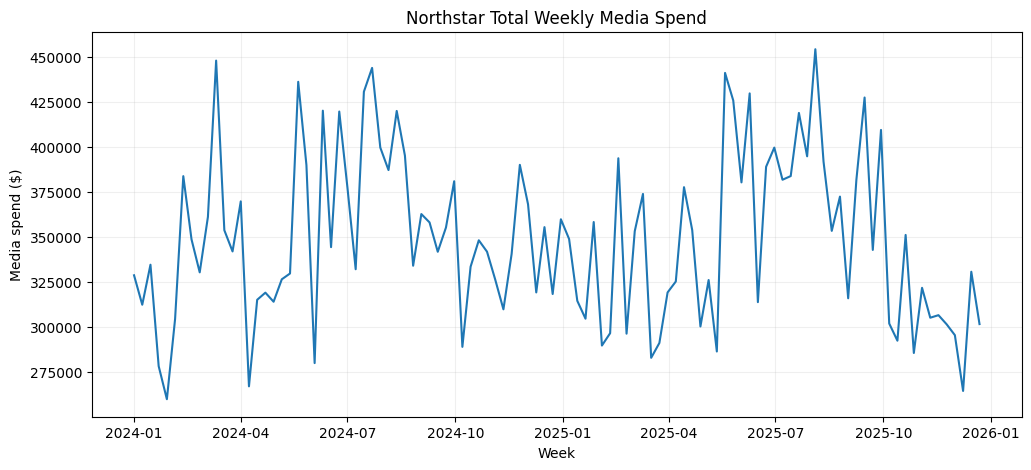

In [ ]:

plt.figure(figsize=(12, 5))
plt.plot(weekly["week"], weekly["total_media_spend"])
plt.title("Northstar Total Weekly Media Spend")
plt.xlabel("Week")
plt.ylabel("Media spend ($)")
plt.grid(alpha=0.2)
plt.show()


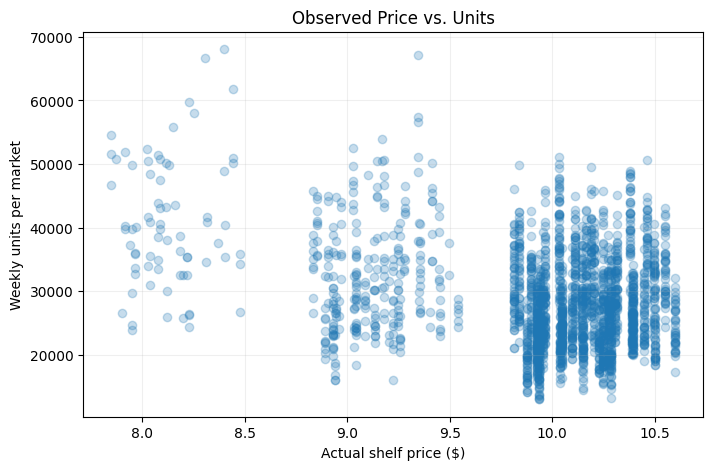

In [ ]:

plt.figure(figsize=(8, 5))
plt.scatter(
    modeling_data["actual_price"],
    modeling_data["units"],
    alpha=0.25,
)
plt.title("Observed Price vs. Units")
plt.xlabel("Actual shelf price ($)")
plt.ylabel("Weekly units per market")
plt.grid(alpha=0.2)
plt.show()



### A warning about the price scatterplot

Do **not** expect the raw slope of price vs. units to equal the true elasticity.

Promotions are more likely when demand is soft, markets differ in size, distribution changes over time, and media also moves with demand.

That is intentional.

Later, pricing models will have to isolate the causal effect of price rather than merely reading a correlation.


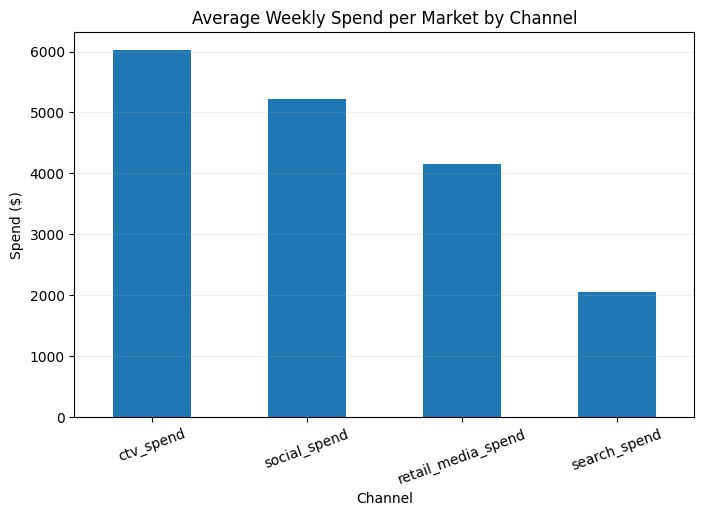

In [ ]:

spend_by_channel = modeling_data[
    ["ctv_spend", "social_spend", "retail_media_spend", "search_spend"]
].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
spend_by_channel.plot(kind="bar")
plt.title("Average Weekly Spend per Market by Channel")
plt.xlabel("Channel")
plt.ylabel("Spend ($)")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.2)
plt.show()



## 15. Demonstrate the built-in confounding

Paid Social spend was designed to be positively related to an unobserved local demand shock.

This is precisely the sort of mechanism that can cause an observational MMM to overstate incrementality if the confounding is not adequately controlled.

We inspect it here because **we are the simulation designers**. In later modeling notebooks, `latent_demand_shock` will be unavailable.


In [ ]:

confounding_check = simulation_truth[
    ["social_spend", "search_spend", "latent_demand_shock", "seasonality_index"]
].corr()

confounding_check


,social_spend,search_spend,latent_demand_shock,seasonality_index
social_spend,1.000000,0.127860,0.165731,0.068949
search_spend,0.127860,1.000000,0.068739,0.054964
latent_demand_shock,0.165731,0.068739,1.000000,-0.039938
seasonality_index,0.068949,0.054964,-0.039938,1.000000


## 16. Save the modeling data and simulation truth

In [ ]:

modeling_path = DATA_DIR / "northstar_modeling_data.csv"
truth_path = DATA_DIR / "northstar_simulation_truth.csv"
params_path = DATA_DIR / "northstar_true_parameters.json"

modeling_data.to_csv(modeling_path, index=False)
simulation_truth.to_csv(truth_path, index=False)

with open(params_path, "w") as f:
    json.dump(TRUTH, f, indent=2)

print("Saved:")
print(modeling_path)
print(truth_path)
print(params_path)


Saved:
/content/drive/MyDrive/northstar_cpg/data/northstar_modeling_data.csv
/content/drive/MyDrive/northstar_cpg/data/northstar_simulation_truth.csv
/content/drive/MyDrive/northstar_cpg/data/northstar_true_parameters.json



#Summary

At the end of Notebook 01 we have:

1. A 20-market × 104-week CPG dataset.
2. Base price and promotional pricing.
3. Competitor pricing.
4. Distribution growth.
5. Four media channels.
6. Channel-specific adstock and saturation.
7. Market-level price elasticity heterogeneity.
8. Profit economics.
9. Deliberate observational confounding.
10. A separate hidden simulation truth for later validation.
